# BANKING77 — EDA and preprocessing

Explore training requests, lightly clean the text, and save development splits. The official test split stays untouched for final evaluation.

Select the project `.venv` kernel. In a new environment, install once with `%pip install datasets pandas matplotlib scikit-learn`.

In [2]:
import sys
!{sys.executable} -m pip install datasets pandas matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 6.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 11.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 60.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 133.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 64.6 MB/s  0:00:00m0:00:0100:01
  Attempting uninstall: fsspec━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/16 [pyarrow]
    Found existing installation: fsspec 2026.9.0━━━━━━━━━━━━━━  1/16 [pyarrow]
    Uninstalling fsspec-2026.9.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/16 [pyarrow]
      Successfully uninstalled fsspec-2026.9.0━━━━━━━━━━━━━━━━  1/16 [pyarrow]
  Attempting uninstall: huggingface-hub90m╺━━━━━━━━━━━━━━ 10/16 [pandas]
    Found existing installation: huggingface_hub 0.36.2━━━━━━━ 10/16 [pandas]
    Uninstalling huggingface_hub-0.36.2:━━━━━━━━━━━━━━ 10/16 [pandas]
      Successfully uninstalled huggingface_hub-0.36.2━━━━━━━━━ 1

In [6]:
from datasets import load_dataset

ds = load_dataset("PolyAI/banking77")

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

In [7]:
import json
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

## 1. Look at the training data

Read intent names from the dataset metadata so their IDs stay correct.

In [8]:
labels = ds["train"].features["label"].names
train = ds["train"].to_pandas().rename(columns={"text": "raw_text"})
train["row_id"] = [f"train_{i:05d}" for i in train.index]
train["intent"] = train["label"].map(dict(enumerate(labels)))

print(f"Training requests: {len(train):,} | Intents: {len(labels)}")
display(train.sample(5, random_state=42))
display(train.isna().sum().rename("missing values").to_frame())
print("Blank requests:", train["raw_text"].str.strip().eq("").sum())
print("Exact duplicate requests:", train["raw_text"].duplicated().sum())

Training requests: 10,003 | Intents: 77


,raw_text,label,row_id,intent
6883,Is it possible for me to change my PIN number?,21,train_06883,change_pin
5836,I'm not sure why my card didn't work,25,train_05836,declined_card_payment
8601,I don't think my top up worked,59,train_08601,top_up_failed
2545,Can you explain why my payment was charged a fee?,15,train_02545,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,5,train_08697,balance_not_updated_after_bank_transfer


,missing values
raw_text,0
label,0
row_id,0
intent,0


Blank requests: 0
Exact duplicate requests: 0


## 2. Intent balance and request lengths

Use whitespace word counts for a quick length overview. These are not transformer token lengths.

,requests per intent
count,77.000000
mean,129.909091
std,32.942207
min,35.000000
25%,112.000000
50%,127.000000
75%,159.000000
max,187.000000


,word_count,character_count
count,10003.000000,10003.000000
mean,11.949415,59.473758
std,7.891577,40.867901
min,2.000000,13.000000
50%,10.000000,47.000000
90%,22.000000,109.800000
95%,29.000000,151.900000
99%,43.000000,220.980000
max,79.000000,433.000000


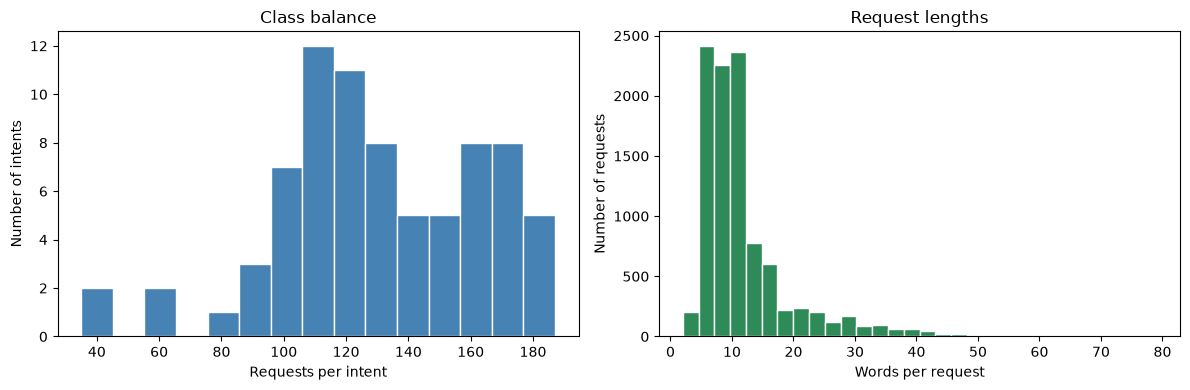

,requests
intent,
contactless_not_working,35
virtual_card_not_working,41
card_acceptance,59
card_swallowed,61
lost_or_stolen_card,82
cash_withdrawal_charge,177
wrong_amount_of_cash_received,180
balance_not_updated_after_cheque_or_cash_deposit,181
direct_debit_payment_not_recognised,182


In [9]:
intent_counts = train["intent"].value_counts().sort_values()
train["word_count"] = train["raw_text"].str.split().str.len()
train["character_count"] = train["raw_text"].str.len()

display(intent_counts.describe().to_frame("requests per intent"))
display(train[["word_count", "character_count"]].describe(percentiles=[.5, .9, .95, .99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(intent_counts, bins=15, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Requests per intent", ylabel="Number of intents", title="Class balance")
axes[1].hist(train["word_count"], bins=30, color="seagreen", edgecolor="white")
axes[1].set(xlabel="Words per request", ylabel="Number of requests", title="Request lengths")
plt.tight_layout()
plt.show()

display(pd.concat([intent_counts.head(5), intent_counts.tail(5)]).to_frame("requests"))

## 3. Light cleaning and duplicate check

`clean_text()` normalizes Unicode and collapses extra whitespace. It preserves case, punctuation, numbers, and negation. Keep `raw_text` alongside `text_clean`.

Use a separate, case-insensitive key to group duplicate requests before splitting.

In [10]:
def clean_text(text):
    return " ".join(unicodedata.normalize("NFC", text).split())


def duplicate_key(text):
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())


train["text_clean"] = train["raw_text"].map(clean_text)
train["duplicate_key"] = train["raw_text"].map(duplicate_key)

display(train[["raw_text", "text_clean", "intent"]].sample(5, random_state=42))

duplicates = train[train["duplicate_key"].duplicated(keep=False)]
print("Duplicate groups after normalization:", duplicates["duplicate_key"].nunique())
print("Groups with conflicting labels:", train.groupby("duplicate_key")["label"].nunique().gt(1).sum())
display(duplicates.sort_values("duplicate_key")[["row_id", "raw_text", "intent"]])

,raw_text,text_clean,intent
6883,Is it possible for me to change my PIN number?,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


Duplicate groups after normalization: 4
Groups with conflicting labels: 0


,row_id,raw_text,intent
6910,train_06910,Do I need to go to a physical bank to change m...,change_pin
6965,train_06965,\nDo I need to go to a physical bank to change...,change_pin
1246,train_01246,I can't seem to be able to use my card,card_not_working
1290,train_01290,\nI can't seem to be able to use my card\n\n\n,card_not_working
1710,train_01710,\nI put the wrong pin too many times and now i...,pin_blocked
1724,train_01724,I put the wrong pin too many times and now it ...,pin_blocked
4594,train_04594,Where can I withdraw money from?,atm_support
4595,train_04595,\nWhere can I withdraw money from?,atm_support


## 4. Create development splits

Use roughly 80% for fitting, 10% for model selection, and 10% for routing-threshold selection. Ten stratified group folds keep normalized duplicates together; fold 0 is model validation and fold 1 is routing validation. Keep every request and its original label.

This simple check groups exact normalized duplicates, not semantic paraphrases. No vocabulary, IDF weights, or model is fitted here.

In [ ]:
splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
train["split"] = "fit"

for fold, (_, indices) in enumerate(splitter.split(train, train["label"], groups=train["duplicate_key"])):
    if fold < 2:
        train.loc[indices, "split"] = ["model_validation", "routing_validation"][fold]

split_summary = train.groupby("split").agg(requests=("row_id", "size"), intents=("label", "nunique"))
split_summary["percent"] = (100 * split_summary["requests"] / len(train)).round(1)
display(split_summary)
print("Duplicate groups spanning splits:", train.groupby("duplicate_key")["split"].nunique().gt(1).sum())

## 5. Save the prepared data

CSV files keep raw text, cleaned text, labels, and row IDs. Only official-training partitions are exported. Rerunning this cell replaces these files.

Use `text_clean` as model input. Fit TF-IDF only on `fit.csv`; pretrained encoders apply their own tokenizer. Tokenization and optional lemmatization comparisons belong in the training stage.

In [ ]:
output = Path("data/processed")
output.mkdir(parents=True, exist_ok=True)
columns = ["row_id", "raw_text", "text_clean", "label", "intent"]

for split, rows in train.groupby("split"):
    rows[columns].to_csv(output / f"{split}.csv", index=False)

train[["row_id", "duplicate_key", "split"]].to_csv(output / "split_assignments.csv", index=False)
(output / "labels.json").write_text(json.dumps(labels, indent=2), encoding="utf-8")
print("Saved to", output.resolve())

## References

- [Casanueva et al. (2020), BANKING77 and dual sentence encoders](https://aclanthology.org/2020.nlp4convai-1.5/): dataset and frozen-encoder motivation.
- [Reimers & Gurevych (2019), Sentence-BERT](https://aclanthology.org/D19-1410/): sentence embeddings for cosine similarity.
- [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2): use the encoder's own tokenizer and pooling.
- [BANKING77 dataset card](https://huggingface.co/datasets/PolyAI/banking77): source and CC-BY-4.0 attribution.

These sources inform the pipeline; this notebook does not claim state-of-the-art results or reproduce a paper's evaluation.